In [1]:
import sys
sys.path.append("/home/emgutierrez/Dropbox/edu_luc_collab/2020_jetjet_collision/astrograv_py/modules/")
import numpy as np
from constants_cgs import *
import matplotlib.pyplot as plt

In [79]:
M = 6.5e9
rg = gravConstant * M * solarMass / cLight2
z0_rg = 2.
z0 = z0_rg * rg
z_rg = np.logspace(np.log10(z0_rg), 2.5, 200)
zVec = z_rg * rg
B0 = 10. # Gauss
Ub0 = B0*B0 / (8*np.pi)
bIndex = 1.5
Gamma0 = 0.2
GammaIndex = 0.0
c1 = 4./3. * thomson * Ub0 / np.square(electronRestEnergy)

In [80]:
def Gamma(z):
    return Gamma0 * np.power(z/z0, GammaIndex)

def Ub(z):
    return U0 * np.power(z/z0, - 2.*bIndex) / np.square(Gamma(z))

def E(Z, e, z):
    factor = 2.*bIndex + 3*GammaIndex - 1.
    return e / (1.0 - c1*e*z0/factor * ( np.power(Z/z0, -factor) - np.power(z/z0, -factor) ) )

<ipython-input-93-08c6de1ad0be>:17: RuntimeWarning: invalid value encountered in log10
  plt.plot(np.log10(z_rg), np.log10(E(zVec, g[i]*electronRestEnergy, z)/electronRestEnergy), lw=3,
<ipython-input-93-08c6de1ad0be>:17: RuntimeWarning: invalid value encountered in log10
  plt.plot(np.log10(z_rg), np.log10(E(zVec, g[i]*electronRestEnergy, z)/electronRestEnergy), lw=3,
<ipython-input-93-08c6de1ad0be>:17: RuntimeWarning: invalid value encountered in log10
  plt.plot(np.log10(z_rg), np.log10(E(zVec, g[i]*electronRestEnergy, z)/electronRestEnergy), lw=3,
<ipython-input-93-08c6de1ad0be>:21: RuntimeWarning: invalid value encountered in log10
  plt.plot(np.log10(z_rg), np.log10(E(zVec, g[i]*electronRestEnergy, z)/electronRestEnergy), lw=3,


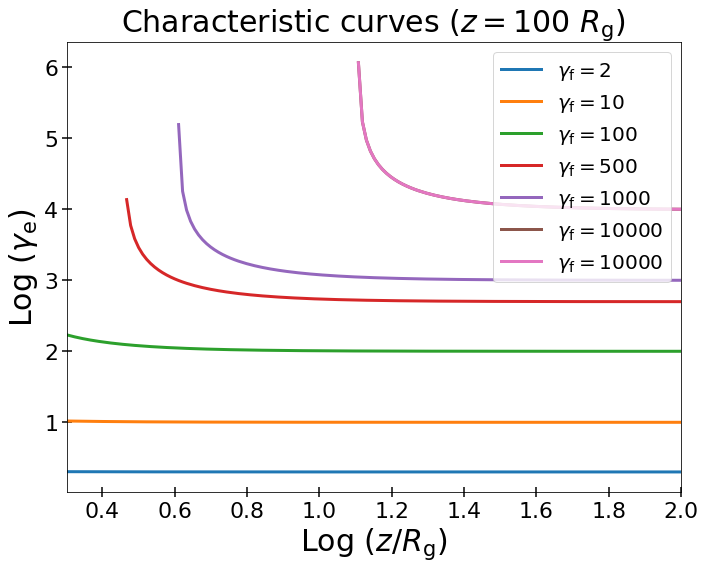

In [93]:
g = np.array([2., 10., 100., 500., 1000., 10000.])
z = 100*rg

fig, ax = plt.subplots(figsize=(10, 8))

ax.set_title(r'Characteristic curves ($z=100~R_{\rm g}$)', fontsize=30)
#ax.set_xscale('log')
#ax.set_yscale('log')
ax.set_xlim([np.log10(z_rg[0]), np.log10(z/rg)])
#ax.set_ylim([1e-15, 1e-10])
ax.set_xlabel(r'$ {\rm Log}~(z / R_{\rm g})$', fontsize=30)
ax.set_ylabel(r'$ {\rm Log} ~(\gamma_{\rm e})$', fontsize=30)
ax.tick_params(axis='both', which='major', direction='inout', labelsize=22, length=10, width=1.5)
ax.tick_params(axis='both', which='minor', direction='inout', labelsize=22, length=5, width=1.5)

for i in range(6):
    plt.plot(np.log10(z_rg), np.log10(E(zVec, g[i]*electronRestEnergy, z)/electronRestEnergy), lw=3,
             label=r'$\gamma_{\rm f}=$'+str(np.int32(g[i])))
    #plt.plot(E(zVec, g[i]*electronRestEnergy, z)/electronRestEnergy, z_rg, label=r'$\gamma_{\rm f}=$'+str(np.int32(g[i])))

plt.plot(np.log10(z_rg), np.log10(E(zVec, g[i]*electronRestEnergy, z)/electronRestEnergy), lw=3,
             label=r'$\gamma_{\rm f}=$'+str(np.int32(g[i])))

ax.legend(loc='upper right', fontsize=20)    
plt.tight_layout()